In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
%load_ext google.colab.data_table

The google.colab.data_table extension is already loaded. To reload it, use:
  %reload_ext google.colab.data_table


Load the dataset

In [ ]:

import pandas as pd
import numpy as np

# Load the processed customer sentiment dataset
topic_df = pd.read_csv("/content/drive/MyDrive/data science/Phase 6/airline_tweets.csv")
# Inspect the dataset
print("Dataset shape:", topic_df.shape)
print("\nColumns:")
print(topic_df.columns.tolist())

topic_df.head()


Dataset shape: (370863, 7)

Columns:
['tweet_id', 'author_id', 'inbound', 'created_at', 'text', 'response_tweet_id', 'in_response_to_tweet_id']


,tweet_id,author_id,inbound,created_at,text,response_tweet_id,in_response_to_tweet_id
0,332,AirAsiaSupport,False,Tue Oct 31 22:12:55 +0000 2017,"@115797 Hi Loreen,kindly DM us your booking nu...",333,334.0
1,333,115797,True,Tue Oct 31 23:44:59 +0000 2017,@AirAsiaSupport Hi! I have DM u my booking # a...,335,332.0
2,335,AirAsiaSupport,False,Tue Oct 31 23:57:53 +0000 2017,"@115797 Hi Loreen,correction done! :) See you ...","336,337",333.0
3,336,115797,True,Wed Nov 01 00:01:49 +0000 2017,@AirAsiaSupport thank you very much..,NaN,335.0
4,337,115797,True,Thu Nov 09 20:15:48 +0000 2017,@AirAsiaSupport Hi! i would like to know on my...,338,335.0


In [ ]:

# Extract customer messages

topic_df = topic_df[topic_df["inbound"] == True].copy()

# Keep relevant columns
topic_df = topic_df[
    ["tweet_id", "author_id", "created_at", "text"]
].copy()

# Remove missing and empty messages
topic_df.dropna(subset=["text"], inplace=True)

topic_df["text"] = topic_df["text"].astype(str)

topic_df = topic_df[
    topic_df["text"].str.strip() != ""
]

topic_df.drop_duplicates(subset="tweet_id", inplace=True)

topic_df.reset_index(drop=True, inplace=True)

print("Customer messages:", len(topic_df))

topic_df.head()


Customer messages: 198017


,tweet_id,author_id,created_at,text
0,333,115797,Tue Oct 31 23:44:59 +0000 2017,@AirAsiaSupport Hi! I have DM u my booking # a...
1,336,115797,Wed Nov 01 00:01:49 +0000 2017,@AirAsiaSupport thank you very much..
2,337,115797,Thu Nov 09 20:15:48 +0000 2017,@AirAsiaSupport Hi! i would like to know on my...
3,339,115797,Fri Nov 10 18:03:05 +0000 2017,@AirAsiaSupport but i cant see it. i only see ...
4,341,115797,Thu Nov 16 19:21:34 +0000 2017,@AirAsiaSupport Hi Airasia. i want to rebook m...


In [ ]:
print("Dataset shape:", topic_df.shape)

Dataset shape: (198017, 4)


Install BERTopic

In [ ]:
%pip install -q bertopic sentence-transformers umap-learn hdbscan

In [ ]:

import pandas as pd
import numpy as np
import re
import torch

from bertopic import BERTopic
from sentence_transformers import SentenceTransformer

from sklearn.feature_extraction.text import CountVectorizer

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())


PyTorch version: 2.14.1+cu130
GPU available: True


Clean the customer messages

In [ ]:

# Create a copy so we preserve the original text
topic_df["text_clean"] = topic_df["text"].copy()

def clean_tweet(text):

    text = str(text)

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", "", text)

    # Remove usernames and mentions
    text = re.sub(r"@\w+", "", text)

    # Remove RT markers
    text = re.sub(r"\bRT\b", "", text)

    # Remove hashtag symbols but retain the words
    text = re.sub(r"#", "", text)

    # Remove extra whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text

topic_df["text_clean"] = topic_df["text_clean"].apply(clean_tweet)

# Remove empty messages
topic_df = topic_df[
    topic_df["text_clean"].str.strip() != ""
].copy()

topic_df.reset_index(drop=True, inplace=True)

print("Original customer messages:", len(topic_df))
print("\nCleaned message examples:")

topic_df[["text", "text_clean"]].head(10)


Original customer messages: 196526

Cleaned message examples:


,text,text_clean
0,@AirAsiaSupport Hi! I have DM u my booking # a...,Hi! I have DM u my booking and passport pictur...
1,@AirAsiaSupport thank you very much..,thank you very much..
2,@AirAsiaSupport Hi! i would like to know on my...,Hi! i would like to know on my itenerary on ho...
3,@AirAsiaSupport but i cant see it. i only see ...,but i cant see it. i only see itenerary.. no b...
4,@AirAsiaSupport Hi Airasia. i want to rebook m...,Hi Airasia. i want to rebook my return flight....
5,@AirAsiaSupport hi! I have booked my ticket a...,hi! I have booked my ticket and when i see my ...
6,@AirAsiaSupport lost my booking # chua loreen ...,lost my booking chua loreen lee flight z2 129....
7,"@AirAsiaSupport Hi Yana, followed!","Hi Yana, followed!"
8,@AirAsiaSupport Hi Yana I don’t have any DMs f...,Hi Yana I don’t have any DMs from you. Did you...
9,@AirAsiaSupport CAS-19708536-CB92N2 CRM:032660...,CAS-19708536-CB92N2 CRM:0326600 Please check o...


The embedding model

In [ ]:
embedding_model = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2",
    device="cuda" if torch.cuda.is_available() else "cpu"
)

print("Embedding model loaded successfully.")


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Embedding model loaded successfully.


Generate document embeddings

We will convert each customer message into a numerical representation.

In [ ]:

# Select 20,000 customer messages for our pilot
sample_size = 20000

docs = topic_df["text_clean"].sample(
    n=sample_size,
    random_state=42
).tolist()

print("Number of documents:", len(docs))
print("\nExample documents:")

for doc in docs[:5]:
    print("-", doc)


Number of documents: 20000

Example documents:
- Done. Looking fwd to hearing back
- I’m not paying $400 to change tickets either. I’m one stressed out unhappy runner.
- EEGZ4L &amp; also SQM2KX Guest 2 Su Loong Wong - correct dob is 1992 may 28
- Hi Yana, I agree with the charges and will proceed with the payment at the check in counter tomorrow. Thank you :)
- So bothered just got off the phone with by far the worst customer service call.


In [ ]:

embeddings = embedding_model.encode(
    docs,
    batch_size=64,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True
)

print("Embedding shape:", embeddings.shape)


Batches:   0%|          | 0/313 [00:00<?, ?it/s]

Embedding shape: (20000, 384)


20,000 = number of customer messages.



384 = number of numerical features representing each message.

BERTopic uses three important components:
1. UMAP: reduces the 384 embedding dimensions while preserving important relationships between messages.
2. HDBSCAN: groups similar messages into clusters and identifies messages that do not fit a clear cluster.
3. CountVectorizer: extracts representative words from each discovered topic.

Configure UMAP

In [ ]:

from umap import UMAP

umap_model = UMAP(
    n_neighbors=15, #Considers nearby messages when preserving relationships
    n_components=5, #Reduces embeddings to five dimensions
    min_dist=0.0,   #Allows similar messages to form tighter groups
    metric="cosine", #Measures similarity between embeddings
    random_state=42  #
)


Configure HDBSCAN

HDBSCAN identifies groups of related messages.

In [ ]:

from hdbscan import HDBSCAN

hdbscan_model = HDBSCAN(
    min_cluster_size=50, #means that a cluster must contain at least 50 messages.
    min_samples=10,
    metric="euclidean",
    cluster_selection_method="eom",
    prediction_data=True
)


Configure keyword extraction

This component helps BERTopic identify representative words and phrases for each topic.

In [ ]:

from sklearn.feature_extraction.text import CountVectorizer

vectorizer_model = CountVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
    min_df=10,
    max_df=0.9
)


Build the BERTopic model

In [ ]:

topic_model = BERTopic(
    embedding_model=embedding_model,
    umap_model=umap_model,
    hdbscan_model=hdbscan_model,
    vectorizer_model=vectorizer_model,
    calculate_probabilities=False,
    verbose=True
)

print("BERTopic model configured successfully.")


BERTopic model configured successfully.


Train the BERTopic model

In [ ]:

topics, probabilities = topic_model.fit_transform(
    docs,
    embeddings
)

print("Topic modelling completed!")
print("Number of documents:", len(docs))
print("Number of unique topic IDs:", len(set(topics)))


2026-11-13 08:13:41,505 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-11-13 08:14:23,460 - BERTopic - Dimensionality - Completed ✓
2026-11-13 08:14:23,463 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-11-13 08:14:32,771 - BERTopic - Cluster - Completed ✓
2026-11-13 08:14:32,784 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-11-13 08:14:35,139 - BERTopic - Representation - Completed ✓


Topic modelling completed!
Number of documents: 20000
Number of unique topic IDs: 70


Inspect the discovered topics

In [ ]:

topic_info = topic_model.get_topic_info()

print("Number of topics discovered:",
      len(topic_info) - 1)

topic_info.head(20)


Number of topics discovered: 69


,Topic,Count,Name,Representation,Representative_Docs
0,-1,8329,-1_flight_time_plane_flights,"[flight, time, plane, flights, amp, service, h...",[I talked with customer service. There are no ...
1,0,1366,0_bag_baggage_luggage_carry,"[bag, baggage, luggage, carry, checked, lost, ...","[Hi there, looking to bring a bike back in a b..."
2,1,679,1_thank_yes_lol_hate,"[thank, yes, lol, hate, love, experience, guys...","[THANK YOU❤️🐘🐘🐘, Thank you!!! 😊😊, haaa, thank ..."
3,2,613,2_seat_seats_middle_row,"[seat, seats, middle, row, paid, exit, upgrade...","[seats 26 e and f on 101, thanks for the “wind..."
4,3,526,3_food_free_flight_voucher,"[food, free, flight, voucher, add, plane, got,...",[Are you issuing refunds for affected passenge...
5,4,474,4_crew_amazing_great_awesome,"[crew, amazing, great, awesome, flight attenda...",[great flight crew. FA from today in my top 5....
6,5,460,5_dm_sent_reply_message,"[dm, sent, reply, message, email, __email__, s...","[I can’t DM you!!, DM’d, Cek DM Please]"
7,6,456,6_delayed_flight delayed_delay_delayed hours,"[delayed, flight delayed, delay, delayed hours...",[Still NOT mentioning that the flight has been...
8,7,350,7_chicago_view_dallas_vegas,"[chicago, view, dallas, vegas, charlotte, seat...","[NUPSNT, my flight from Chicago-Midway to Cinc..."
9,8,343,8_customer_customer service_service_customers,"[customer, customer service, service, customer...","[Thank you for amazing customer service!, I lo..."


The -1 topic is the outlier group, not a meaningful discovered topic.Its a message that HDBSCAN could not confidently place in a sufficiently dense cluster

The output:
- Topic: topic identification number.
- Count: number of messages assigned to that topic.
- Name: automatically generated topic name.
- Representation: representative keywords.
- Representative_Docs: representative messages, depending on the BERTopic version.

Configure a second HDBSCAN model

In [ ]:

hdbscan_model_v2 = HDBSCAN(
    min_cluster_size=50,
    min_samples=5,
    metric="euclidean",
    cluster_selection_method="eom",
    prediction_data=True
)


Build the second BERTopic model

In [ ]:

topic_model_v2 = BERTopic(
    embedding_model=embedding_model,
    umap_model=umap_model,
    hdbscan_model=hdbscan_model_v2,
    vectorizer_model=vectorizer_model,
    calculate_probabilities=False,
    verbose=True
)


Train the second model

In [ ]:

topics_v2, probabilities_v2 = topic_model_v2.fit_transform(
    docs,
    embeddings
)

print("Second model training completed!")


2026-11-13 08:14:37,092 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-11-13 08:14:59,276 - BERTopic - Dimensionality - Completed ✓
2026-11-13 08:14:59,279 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-11-13 08:15:00,604 - BERTopic - Cluster - Completed ✓
2026-11-13 08:15:00,613 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-11-13 08:15:01,153 - BERTopic - Representation - Completed ✓


Second model training completed!


Compare the two models

In [ ]:

def compare_models(model, topics, model_name):

    total = len(topics)
    outliers = sum(t == -1 for t in topics)
    discovered = len(set(topics)) - (1 if -1 in topics else 0)

    return {
        "Model": model_name,
        "Total Messages": total,
        "Discovered Topics": discovered,
        "Outlier Messages": outliers,
        "Outlier Percentage": round(outliers / total * 100, 2),
        "Assigned Messages": total - outliers
    }

comparison = pd.DataFrame([
    compare_models(topic_model, topics, "Model 1"),
    compare_models(topic_model_v2, topics_v2, "Model 2")
])

comparison


,Model,Total Messages,Discovered Topics,Outlier Messages,Outlier Percentage,Assigned Messages
0,Model 1,20000,69,8329,41.64,11671
1,Model 2,20000,71,8009,40.04,11991


Inspect Model 2 topics

In [ ]:

topic_info_v2 = topic_model_v2.get_topic_info()

# Exclude outliers
topic_info_v2 = topic_info_v2[
    topic_info_v2["Topic"] != -1
]

# Display the 30 largest topics
topic_info_v2 = topic_info_v2.sort_values(
    by="Count",
    ascending=False
)

topic_info_v2[
    ["Topic", "Count", "Name", "Representation"]
].head(30)


,Topic,Count,Name,Representation
1,0,1364,0_bag_baggage_luggage_carry,"[bag, baggage, luggage, carry, checked, lost, ..."
2,1,639,1_yes_lol_love_hate,"[yes, lol, love, hate, experience, guys, haha,..."
3,2,612,2_seat_seats_row_middle,"[seat, seats, row, middle, paid, window, exit,..."
4,3,551,3_food_free_club_voucher,"[food, free, club, voucher, flight, add, plane..."
5,4,542,4_crew_amazing_great_awesome,"[crew, amazing, great, awesome, great flight, ..."
6,5,449,5_delayed_flight delayed_delay_flight,"[delayed, flight delayed, delay, flight, delay..."
7,6,401,6_chicago_atlanta_view_dallas,"[chicago, atlanta, view, dallas, charlotte, se..."
8,7,310,7_delta_fly_sky_app,"[delta, fly, sky, app, twitter, airlines, flig..."
9,8,284,8_change_price_fee_200,"[change, price, fee, 200, tickets, fare, fees,..."
10,9,282,9_dm_sent_just sent_reply,"[dm, sent, just sent, reply, urgent, send, che..."


Visualise the topic clusters

In [ ]:

topic_model_v2.visualize_topics()


Topics that are close together have more similar representations.

In [ ]:
#displays the important words associated with each topic.
topic_model_v2.visualize_barchart(
    top_n_topics=15,
    n_words=10,
    height=700
)


This shows the most representative words for the largest topics.

Create a reduced-topic experiment

In [ ]:

import copy

# Preserve the original Model 2
topic_model_reduced = copy.deepcopy(topic_model_v2)

# Automatically reduce semantically similar topics
topic_model_reduced.reduce_topics(
    docs,
    nr_topics="auto" #allows BERTopic to merge similar topics based on their representations.
)

print("Topic reduction completed!")

reduced_topic_info = topic_model_reduced.get_topic_info()

print(
    "Topics after reduction:",
    len(reduced_topic_info) - 1
)

reduced_topic_info.head(30)


2026-11-13 08:15:02,295 - BERTopic - Topic reduction - Reducing number of topics
2026-11-13 08:15:02,320 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-11-13 08:15:02,856 - BERTopic - Representation - Completed ✓
2026-11-13 08:15:02,861 - BERTopic - Topic reduction - Reduced number of topics from 72 to 59


Topic reduction completed!
Topics after reduction: 58


,Topic,Count,Name,Representation,Representative_Docs
0,-1,8009,-1_flight_time_plane_service,"[flight, time, plane, service, flights, amp, h...",[So makes us board already knowing there is a ...
1,0,1895,0_delayed_flight_app_refund,"[delayed, flight, app, refund, gate, cancelled...",[Now the rescheduled flight is now delayed 😳😂😂...
2,1,1364,1_bag_baggage_luggage_carry,"[bag, baggage, luggage, carry, checked, check,...",[Who brought the red bag? When the luggage mat...
3,2,1096,2_lax_crew_amazing_great,"[lax, crew, amazing, great, sfo, flight, atlan...",[Had a great flight with the outstanding crew ...
4,3,639,3_yes_love_lol_hate,"[yes, love, lol, hate, experience, guys, haha,...","[Yes, Yes I am, Yes 😪]"
5,4,612,4_seat_seats_row_middle,"[seat, seats, row, middle, paid, extra, upgrad...","[seats 26 e and f on 101, thanks for the “wind..."
6,5,551,5_food_free_club_flight,"[food, free, club, flight, voucher, add, plane...","[hi can i add on food after check in ??, 48......"
7,6,310,6_delta_fly_app_sky,"[delta, fly, app, sky, twitter, flight, airlin...",[I have up was disrespected and spoken to in a...
8,7,284,7_change_price_fee_200,"[change, price, fee, 200, tickets, fare, ticke...",[I want to change my flight tickets but then t...
9,8,282,8_dm_sent_reply_urgent,"[dm, sent, reply, urgent, send, check, hi, pls...",[Can you please DM me it's not accepting my me...


Compare the results

In [ ]:

print("Original topics:", len(topic_model_v2.get_topic_info()) - 1)

print("Reduced topics:", len(topic_model_reduced.get_topic_info()) - 1)

print("\nReduced topic distribution:")

reduced_topic_info[
    ["Topic", "Count", "Name", "Representation"]
].head(30)


Original topics: 71
Reduced topics: 58

Reduced topic distribution:


,Topic,Count,Name,Representation
0,-1,8009,-1_flight_time_plane_service,"[flight, time, plane, service, flights, amp, h..."
1,0,1895,0_delayed_flight_app_refund,"[delayed, flight, app, refund, gate, cancelled..."
2,1,1364,1_bag_baggage_luggage_carry,"[bag, baggage, luggage, carry, checked, check,..."
3,2,1096,2_lax_crew_amazing_great,"[lax, crew, amazing, great, sfo, flight, atlan..."
4,3,639,3_yes_love_lol_hate,"[yes, love, lol, hate, experience, guys, haha,..."
5,4,612,4_seat_seats_row_middle,"[seat, seats, row, middle, paid, extra, upgrad..."
6,5,551,5_food_free_club_flight,"[food, free, club, flight, voucher, add, plane..."
7,6,310,6_delta_fly_app_sky,"[delta, fly, app, sky, twitter, flight, airlin..."
8,7,284,7_change_price_fee_200,"[change, price, fee, 200, tickets, fare, ticke..."
9,8,282,8_dm_sent_reply_urgent,"[dm, sent, reply, urgent, send, check, hi, pls..."


Inspect the original topics beyond the top 30

In [ ]:
topic_info_original = topic_model_v2.get_topic_info()

topic_info_original = topic_info_original[
    topic_info_original["Topic"] != -1
]

topic_info_original = topic_info_original.sort_values(
    by="Count",
    ascending=False
)

display(
    topic_info_original[
        ["Topic", "Count", "Name", "Representation"]
    ]
)

,Topic,Count,Name,Representation
1,0,1364,0_bag_baggage_luggage_carry,"[bag, baggage, luggage, carry, checked, lost, ..."
2,1,639,1_yes_lol_love_hate,"[yes, lol, love, hate, experience, guys, haha,..."
3,2,612,2_seat_seats_row_middle,"[seat, seats, row, middle, paid, window, exit,..."
4,3,551,3_food_free_club_voucher,"[food, free, club, voucher, flight, add, plane..."
5,4,542,4_crew_amazing_great_awesome,"[crew, amazing, great, awesome, great flight, ..."
...,...,...,...,...
67,66,52,66_thank thank_appreciate__,"[thank thank, appreciate, , , , , , , , ]"
68,67,51,67_apology_sorry_apologies_inconvenience,"[apology, sorry, apologies, inconvenience, fau..."
69,68,51,68_sent_just sent_send_thank help,"[sent, just sent, send, thank help, ok, pm, re..."
70,69,50,69_birthday_wedding_happy_special,"[birthday, wedding, happy, special, miss, miss..."


Examine the original topics with representative documents

In [ ]:
for topic_id in topic_info_original["Topic"].head(20):

    print("\n" + "=" * 80)
    print("TOPIC:", topic_id)

    print("\nKeywords:")
    print(topic_model_v2.get_topic(topic_id))

    print("\nRepresentative documents:")

    docs_for_topic = topic_model_v2.get_representative_docs(
        topic_id
    )

    for doc in docs_for_topic[:3]:
        print("-", doc[:250])


TOPIC: 0

Keywords:
[('bag', np.float64(0.06973722932732586)), ('baggage', np.float64(0.05088514970795125)), ('luggage', np.float64(0.04876115098799172)), ('carry', np.float64(0.02815220248539919)), ('checked', np.float64(0.025606849423831474)), ('lost', np.float64(0.023909673949306466)), ('check', np.float64(0.023400071381226926)), ('claim', np.float64(0.01590672078483236)), ('drop', np.float64(0.0127781750766082)), ('hand', np.float64(0.012108667739399781))]

Representative documents:
- lost my bag oversees. Can you help?
- my bag has tire marks all over it and was ripped to shreds. How do I get a new bag?
- Not thrilled to have to check carry-on at gate for fear of lost luggage but notifications from when bag is loaded on plane are great!

TOPIC: 1

Keywords:
[('yes', np.float64(0.0678182298121484)), ('lol', np.float64(0.04603371771033252)), ('love', np.float64(0.045465238977180335)), ('hate', np.float64(0.044392397457397405)), ('experience', np.float64(0.042250984134491215)), ('gu

Improve the keywords BERTopic displays, without changing the existing topic assignments.

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer

custom_stopwords = [
    "thank",
    "thanks",
    "thx",
    "thankyou",
    "just",
    "guys",
    "lol",
    "haha",
    "yes",
    "okay",
    "ok",
    "hi",
    "hey",
    "please",
    "pls"
]

vectorizer_model_custom = CountVectorizer(
    stop_words=custom_stopwords + list(
        CountVectorizer(stop_words="english").get_stop_words()
    ),
    ngram_range=(1, 2),
    min_df=10,
    max_df=0.9
)

topic_model_v2.update_topics(
    docs,
    vectorizer_model=vectorizer_model_custom
)

print("Topic representations updated successfully!")

Topic representations updated successfully!


In [ ]:
updated_topic_info = topic_model_v2.get_topic_info()

display(
    updated_topic_info[
        ["Topic", "Count", "Name", "Representation"]
    ].head(30)
)

,Topic,Count,Name,Representation
0,-1,8009,-1_flight_time_plane_service,"[flight, time, plane, service, flights, amp, h..."
1,0,1364,0_bag_baggage_luggage_carry,"[bag, baggage, luggage, carry, checked, lost, ..."
2,1,639,1_love_hate_experience_fuck,"[love, hate, experience, fuck, suck, oh, rock,..."
3,2,612,2_seat_seats_row_middle,"[seat, seats, row, middle, paid, window, exit,..."
4,3,551,3_food_free_club_voucher,"[food, free, club, voucher, flight, add, loung..."
5,4,542,4_crew_amazing_great_awesome,"[crew, amazing, great, awesome, great flight, ..."
6,5,449,5_delayed_flight delayed_delay_delayed hours,"[delayed, flight delayed, delay, delayed hours..."
7,6,401,6_chicago_atlanta_view_dallas,"[chicago, atlanta, view, dallas, charlotte, se..."
8,7,310,7_delta_fly_sky_app,"[delta, fly, sky, app, twitter, airlines, lax,..."
9,8,284,8_change_price_fee_200,"[change, price, fee, 200, tickets, fare, fees,..."


save your pilot model

In [ ]:
topic_model_v2.save(
    "airline_bertopic_model_v2",
    serialization="safetensors",
    save_ctfidf=True,
    save_embedding_model="sentence-transformers/all-MiniLM-L6-v2"
)

print("Pilot BERTopic model saved successfully!")

Pilot BERTopic model saved successfully!


save the pilot topic assignments

In [ ]:
pilot_sample = topic_df.sample(
    n=20000,
    random_state=42
).copy()

pilot_sample = pilot_sample.reset_index(drop=True)

pilot_results = pilot_sample[
    ["tweet_id", "text", "text_clean"]
].copy()

pilot_results["topic"] = topics_v2

pilot_results.to_csv(
    "airline_pilot_topic_assignments.csv",
    index=False
)

Investigate overlapping topics

In [ ]:
topics_to_inspect = [3, 25, 16, 24, 9, 21]

for topic_id in topics_to_inspect:

    print("\n" + "=" * 70)
    print(f"TOPIC: {topic_id}")

    # Display topic keywords
    print("\nKeywords:")
    print(topic_model_v2.get_topic(topic_id))

    # Display representative documents
    print("\nRepresentative documents:")

    representative_docs = (
        topic_model_v2.get_representative_docs(topic_id)
    )

    for i, doc in enumerate(representative_docs[:5], 1):
        print(f"{i}. {doc[:200]}")


TOPIC: 3

Keywords:
[('food', np.float64(0.07714294282723967)), ('free', np.float64(0.03053054980097924)), ('club', np.float64(0.02053855371931087)), ('voucher', np.float64(0.016434878139962306)), ('flight', np.float64(0.01593366077303325)), ('add', np.float64(0.015065773321009451)), ('lounge', np.float64(0.013448619156122374)), ('plane', np.float64(0.013431542749732822)), ('really', np.float64(0.012930681571801059)), ('got', np.float64(0.011957027121290422))]

Representative documents:
1. 48... now delayed waiting for catering. Really ?!?! Is the food that good ??
2. why did you guys get rid of the food Network on your free tv app? 😩
3. Admiral’sClub in Santiago- thanks for the upgrades in food and atmosphere! Fabulous meal before flight!

TOPIC: 25

Keywords:
[('thanksgiving', np.float64(0.121165245588418)), ('ride', np.float64(0.04415228752633434)), ('family', np.float64(0.04160306027888922)), ('happy', np.float64(0.034611750689953945)), ('home', np.float64(0.03393620112612996)), (

calculate the coverage of our pilot model

In [ ]:
# Total pilot documents
total_documents = len(topics_v2)

# Outlier documents
outlier_count = sum(
    topic == -1 for topic in topics_v2
)

# Assigned documents
assigned_count = total_documents - outlier_count

# Calculate percentages
outlier_percentage = (
    outlier_count / total_documents
) * 100

assigned_percentage = (
    assigned_count / total_documents
) * 100

print("PILOT MODEL COVERAGE")
print("-" * 40)

print("Total documents:", total_documents)
print("Assigned documents:", assigned_count)
print("Outlier documents:", outlier_count)

print(f"Assigned percentage: {assigned_percentage:.2f}%")
print(f"Outlier percentage: {outlier_percentage:.2f}%")

PILOT MODEL COVERAGE
----------------------------------------
Total documents: 20000
Assigned documents: 11991
Outlier documents: 8009
Assigned percentage: 59.96%
Outlier percentage: 40.04%


Prepare the full dataset

In [ ]:
# Check the full customer dataset

print("FULL DATASET PREPARATION")
print("-" * 40)

print("Total customer messages:", len(topic_df))

print("\nMissing text values:")
print(topic_df["text_clean"].isna().sum())

print("\nEmpty text values:")
print(
    (topic_df["text_clean"].str.strip() == "").sum()
)

print("\nDuplicate tweet IDs:")
print(topic_df["tweet_id"].duplicated().sum())

print("\nDataset memory usage:")
print(
    round(
        topic_df.memory_usage(deep=True).sum() / (1024**2),
        2
    ),
    "MB"
)

FULL DATASET PREPARATION
----------------------------------------
Total customer messages: 196526

Missing text values:
0

Empty text values:
0

Duplicate tweet IDs:
0

Dataset memory usage:
105.69 MB


Create a folder for the final model

In [ ]:
import os

output_dir = "/content/drive/MyDrive/data science/Phase 6/BERTopic"

os.makedirs(output_dir, exist_ok=True)

print("Output directory ready:", output_dir)

Output directory ready: /content/drive/MyDrive/data science/Phase 6/BERTopic


Prepare the full documents

In [ ]:
# Preserve the cleaned dataset and its row order
full_topic_df = topic_df.reset_index(drop=True).copy()

# Extract documents
docs_full = (
    full_topic_df["text_clean"]
    .astype(str)
    .tolist()
)

# Preserve tweet IDs for later joining
tweet_ids_full = full_topic_df["tweet_id"].tolist()

print("Documents:", len(docs_full))
print("Tweet IDs:", len(tweet_ids_full))
print("First document:", docs_full[0])

Documents: 196526
Tweet IDs: 196526
First document: Hi! I have DM u my booking and passport picture thanks so much for quick action


Save the message IDs

In [ ]:
metadata = full_topic_df[["tweet_id", "created_at"]].copy()

metadata.to_csv(
    f"{output_dir}/full_topic_metadata.csv",
    index=False
)

print("Message metadata saved!")

Message metadata saved!


Generate embeddings in batches

In [ ]:
import numpy as np
import os

chunk_size = 10000

for start in range(0, len(docs_full), chunk_size):

    end = min(start + chunk_size, len(docs_full))

    chunk_path = (
        f"{output_dir}/embeddings_{start}_{end}.npy"
    )

    # Skip completed chunks if resuming
    if os.path.exists(chunk_path):
        print(f"Skipping completed chunk: {start} - {end}")
        continue

    print(f"\nProcessing messages {start} to {end}")

    chunk_docs = docs_full[start:end]

    chunk_embeddings = embedding_model.encode(
        chunk_docs,
        batch_size=64,
        show_progress_bar=True,
        convert_to_numpy=True,
        normalize_embeddings=True
    )

    np.save(chunk_path, chunk_embeddings)

    print("Saved:", chunk_path)
    print("Embedding shape:", chunk_embeddings.shape)

print("\nAll embedding chunks processed!")

Skipping completed chunk: 0 - 10000
Skipping completed chunk: 10000 - 20000
Skipping completed chunk: 20000 - 30000
Skipping completed chunk: 30000 - 40000
Skipping completed chunk: 40000 - 50000
Skipping completed chunk: 50000 - 60000
Skipping completed chunk: 60000 - 70000
Skipping completed chunk: 70000 - 80000
Skipping completed chunk: 80000 - 90000
Skipping completed chunk: 90000 - 100000
Skipping completed chunk: 100000 - 110000
Skipping completed chunk: 110000 - 120000
Skipping completed chunk: 120000 - 130000
Skipping completed chunk: 130000 - 140000
Skipping completed chunk: 140000 - 150000
Skipping completed chunk: 150000 - 160000
Skipping completed chunk: 160000 - 170000
Skipping completed chunk: 170000 - 180000
Skipping completed chunk: 180000 - 190000
Skipping completed chunk: 190000 - 196526

All embedding chunks processed!


Combine the embedding chunks

In [ ]:
embedding_chunks = []

for start in range(0, len(docs_full), chunk_size):

    end = min(start + chunk_size, len(docs_full))

    chunk_path = (
        f"{output_dir}/embeddings_{start}_{end}.npy"
    )

    chunk = np.load(chunk_path)
    embedding_chunks.append(chunk)

embeddings_full = np.concatenate(
    embedding_chunks,
    axis=0
)

print("Full embeddings shape:", embeddings_full.shape)

Full embeddings shape: (196526, 384)


In [ ]:
np.save(
    f"{output_dir}/airline_full_embeddings.npy",
    embeddings_full
)

print("Full embeddings saved successfully!")

Full embeddings saved successfully!


Configure the final BERTopic model

In [ ]:
from bertopic import BERTopic
from umap import UMAP
from hdbscan import HDBSCAN
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# Check that documents and embeddings are aligned
assert len(docs_full) == len(embeddings_full)
assert embeddings_full.shape == (len(docs_full), 384)

# Custom stopwords used in the pilot
custom_stopwords = [
    "thank", "thanks", "thx", "thankyou",
    "just", "guys", "lol", "haha",
    "yes", "okay", "ok", "hi", "hey",
    "please", "pls"
]

all_stopwords = list(
    ENGLISH_STOP_WORDS.union(custom_stopwords)
)

# UMAP configuration
umap_model_full = UMAP(
    n_neighbors=15,
    n_components=5,
    min_dist=0.0,
    metric="cosine",
    random_state=42
)

# HDBSCAN configuration
hdbscan_model_full = HDBSCAN(
    min_cluster_size=50,
    min_samples=5,
    metric="euclidean",
    cluster_selection_method="eom",
    prediction_data=True
)

# Keyword extraction configuration
vectorizer_model_full = CountVectorizer(
    stop_words=all_stopwords,
    ngram_range=(1, 2),
    min_df=10,
    max_df=0.9
)

print("Final BERTopic components configured successfully!")

Final BERTopic components configured successfully!


The final BERTopic model

In [ ]:
topic_model_full = BERTopic(
    embedding_model=embedding_model,
    umap_model=umap_model_full,
    hdbscan_model=hdbscan_model_full,
    vectorizer_model=vectorizer_model_full,
    calculate_probabilities=False,
    verbose=True
)

print("Full BERTopic model created!")

Full BERTopic model created!


Train on all 196,526 messages

In [ ]:
topics_full, probabilities_full = (
    topic_model_full.fit_transform(
        docs_full,
        embeddings_full
    )
)

print("Full BERTopic training completed!")

2026-11-13 08:27:27,382 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-11-13 08:40:38,083 - BERTopic - Dimensionality - Completed ✓
2026-11-13 08:40:38,093 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-11-13 08:41:06,127 - BERTopic - Cluster - Completed ✓
2026-11-13 08:41:06,183 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-11-13 08:41:11,307 - BERTopic - Representation - Completed ✓


Full BERTopic training completed!


Evaluate the final model

In [ ]:
import numpy as np

total_documents = len(topics_full)

outlier_count = sum(
    topic == -1 for topic in topics_full
)

assigned_count = total_documents - outlier_count

print("=" * 50)
print("FULL BERTopic MODEL RESULTS")
print("=" * 50)

print("Total documents:", total_documents)
print("Discovered topics:", len(set(topics_full)) - 1)
print("Assigned documents:", assigned_count)
print("Outlier documents:", outlier_count)

print(
    "Assigned percentage:",
    round(assigned_count / total_documents * 100, 2),
    "%"
)

print(
    "Outlier percentage:",
    round(outlier_count / total_documents * 100, 2),
    "%"
)

FULL BERTopic MODEL RESULTS
Total documents: 196526
Discovered topics: 473
Assigned documents: 110227
Outlier documents: 86299
Assigned percentage: 56.09 %
Outlier percentage: 43.91 %


Save the final model

In [ ]:
# Save the BERTopic model
topic_model_full.save(
    f"{output_dir}/airline_bertopic_full_model",
    serialization="safetensors",
    save_ctfidf=True,
    save_embedding_model="sentence-transformers/all-MiniLM-L6-v2"
)

# Preserve tweet IDs and their topic assignments
full_topic_results = full_topic_df[
    ["tweet_id", "created_at", "text_clean"]
].copy()

full_topic_results["topic"] = topics_full

full_topic_results.to_csv(
    f"{output_dir}/airline_full_topic_assignments.csv",
    index=False
)

print("Full BERTopic model and assignments saved!")

Full BERTopic model and assignments saved!


inspect the 473 topics

In [ ]:
# Retrieve topic information
topic_info_full = topic_model_full.get_topic_info()

# Exclude outliers
valid_topics = topic_info_full[
    topic_info_full["Topic"] != -1
].copy()

# Sort by number of messages
valid_topics = valid_topics.sort_values(
    by="Count",
    ascending=False
)

print("Number of regular topics:", len(valid_topics))

display(
    valid_topics[
        ["Topic", "Count", "Name", "Representation"]
    ].head(30)
)

Number of regular topics: 473


,Topic,Count,Name,Representation
1,0,5319,0_seat_seats_row_middle,"[seat, seats, row, middle, window, middle seat..."
2,1,3406,1_delta_fly delta_delta flight_delta comfort,"[delta, fly delta, delta flight, delta comfort..."
3,2,2687,2_airline_airlines_worst airline_worst,"[airline, airlines, worst airline, worst, best..."
4,3,2285,3_crew_flight attendant_attendant_amazing,"[crew, flight attendant, attendant, amazing, r..."
5,4,1840,4_customer_customer service_customers_service,"[customer, customer service, customers, servic..."
6,5,1722,5_wifi_free wifi_wi fi_wi,"[wifi, free wifi, wi fi, wi, fi, wifi flight, ..."
7,6,1718,6_dm_sent dm_dm dm_dm sent,"[dm, sent dm, dm dm, dm sent, sent, reply dm, ..."
8,7,1607,7_gate_gate agent_gate agents_gates,"[gate, gate agent, gate agents, gates, agent, ..."
9,8,1389,8_mr_ms_gender_correction,"[mr, ms, gender, correction, change, married, ..."
10,9,1361,9_jfk_flight jfk_jfk flight_lhr jfk,"[jfk, flight jfk, jfk flight, lhr jfk, jfk lax..."


Visualise the full topic distribution

In [ ]:
topic_model_full.visualize_barchart(
    top_n_topics=20,
    n_words=10,
    height=800
)

In [ ]:
topic_model_full.visualize_topics()

Output hidden; open in https://colab.research.google.com to view.

Save the Model

In [ ]:
topic_model_full.save(
    f"{output_dir}/airline_bertopic_full_model_v1",
    serialization="safetensors",
    save_ctfidf=True,
    save_embedding_model="sentence-transformers/all-MiniLM-L6-v2"
)

print("Full model V1 saved successfully!")

Full model V1 saved successfully!


The topic-size distribution

In [ ]:
topic_sizes = valid_topics["Count"]

print("TOPIC SIZE DISTRIBUTION")
print("-" * 40)

print("Largest topic:", topic_sizes.max())
print("Smallest topic:", topic_sizes.min())
print("Average topic size:", round(topic_sizes.mean(), 2))
print("Median topic size:", topic_sizes.median())



TOPIC SIZE DISTRIBUTION
----------------------------------------
Largest topic: 5319
Smallest topic: 50
Average topic size: 233.04
Median topic size: 115.0


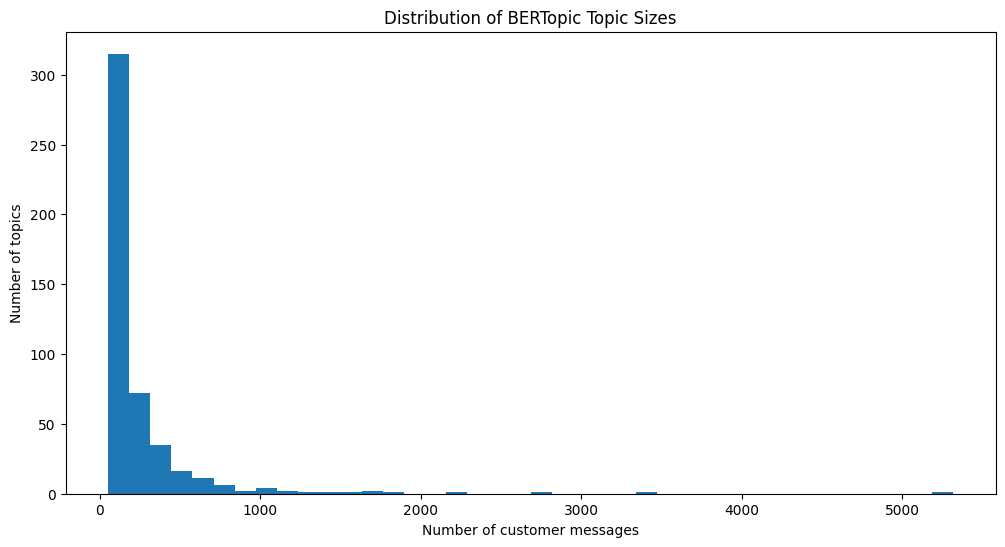

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.hist(
    topic_sizes,
    bins=40
)

plt.title("Distribution of BERTopic Topic Sizes")
plt.xlabel("Number of customer messages")
plt.ylabel("Number of topics")

plt.show()

Creating Business Categories

In [ ]:
# Initial business taxonomy for the top 30 topics

topic_mapping = {
    0:  ("Seating & Cabin Experience", "Seat Selection"),
    1:  ("Airline & Brand Experience", "Delta Discussions"),
    2:  ("Airline & Brand Experience", "Airline Reputation"),
    3:  ("Staff & Service Experience", "Cabin Crew"),
    4:  ("Staff & Service Experience", "Customer Service"),
    5:  ("Digital & Social Media Support", "Inflight Wi-Fi"),
    6:  ("Digital & Social Media Support", "Direct Message Support"),
    7:  ("Staff & Service Experience", "Gate Agents"),
    8:  ("Booking & Passenger Details", "Passenger Details Correction"),
    9:  ("Airport & Route Experience", "JFK Routes"),
    10: ("Loyalty & Rewards", "AAdvantage Programme"),
    11: ("Boarding & Check-in", "Boarding Pass"),
    12: ("Airline & Brand Experience", "Southwest Discussions"),
    13: ("Airport & Route Experience", "LAX Routes"),
    14: ("Loyalty & Rewards", "Miles and Mileage"),
    15: ("Flight Disruptions", "Flight Delays"),
    16: ("Digital & Social Media Support", "Twitter Engagement"),
    17: ("Baggage Services", "Baggage Allowance"),
    18: ("Airport & Route Experience", "Destinations and Hawaii"),
    19: ("Customer Support Accessibility", "Telephone Hold Times"),
    20: ("Flight Disruptions", "Delay Discussions"),
    21: ("Flight Disruptions", "Flight Cancellations"),
    22: ("Airport Lounge Services", "Lounge Access"),
    23: ("Baggage Services", "Lost or Damaged Luggage"),
    24: ("Travel Experience", "General Travel"),
    25: ("Loyalty & Rewards", "Reward Points"),
    26: ("Language & Multilingual Support", "Spanish-language Conversations"),
    27: ("Booking & Passenger Details", "Booking Assistance"),
    28: ("Seating & Cabin Experience", "Overhead Bin Space"),
    29: ("Refunds & Compensation", "Flight Refunds")
}

print("Initial topic mapping created.")
print("Topics mapped:", len(topic_mapping))

Initial topic mapping created.
Topics mapped: 30


In [ ]:
# Create the topic results dataset

topic_results_df = full_topic_df.copy()

# Preserve original topic IDs
topic_results_df["Topic_ID"] = topics_full

# Assign business category
topic_results_df["Business_Category"] = (
    topic_results_df["Topic_ID"]
    .map(lambda x: topic_mapping.get(x, ("Needs Review", "Unmapped Topic"))[0])
)

# Assign business subcategory
topic_results_df["Business_Subcategory"] = (
    topic_results_df["Topic_ID"]
    .map(lambda x: topic_mapping.get(x, ("Needs Review", "Unmapped Topic"))[1])
)

# Give outliers a separate label
outlier_mask = topic_results_df["Topic_ID"] == -1

topic_results_df.loc[outlier_mask, "Business_Category"] = "Outliers"
topic_results_df.loc[outlier_mask, "Business_Subcategory"] = "Unassigned"

print("Mapping applied successfully!")
print("Dataset shape:", topic_results_df.shape)

topic_results_df[
    ["tweet_id", "Topic_ID", "Business_Category", "Business_Subcategory"]
].head(10)

Mapping applied successfully!
Dataset shape: (196526, 8)


,tweet_id,Topic_ID,Business_Category,Business_Subcategory
0,333,27,Booking & Passenger Details,Booking Assistance
1,336,370,Needs Review,Unmapped Topic
2,337,271,Needs Review,Unmapped Topic
3,339,271,Needs Review,Unmapped Topic
4,341,164,Needs Review,Unmapped Topic
5,334,8,Booking & Passenger Details,Passenger Details Correction
6,347,-1,Outliers,Unassigned
7,363,237,Needs Review,Unmapped Topic
8,364,6,Digital & Social Media Support,Direct Message Support
9,367,49,Needs Review,Unmapped Topic


The business category summary

In [ ]:
# Exclude outliers and unmapped topics from the initial summary

mapped_data = topic_results_df[
    topic_results_df["Business_Category"] != "Outliers"
].copy()

mapped_data = mapped_data[
    mapped_data["Business_Category"] != "Needs Review"
]

category_summary = (
    mapped_data.groupby("Business_Category")
    .agg(
        Total_Messages=("tweet_id", "count"),
        Number_of_Topics=("Topic_ID", "nunique")
    )
    .sort_values("Total_Messages", ascending=False)
    .reset_index()
)

category_summary["Percentage"] = (
    category_summary["Total_Messages"] /
    len(mapped_data) * 100
).round(2)

category_summary

,Business_Category,Total_Messages,Number_of_Topics,Percentage
0,Airline & Brand Experience,7167,3,17.98
1,Seating & Cabin Experience,5949,2,14.93
2,Staff & Service Experience,5732,3,14.38
3,Digital & Social Media Support,4355,3,10.93
4,Airport & Route Experience,3164,3,7.94
5,Loyalty & Rewards,2820,3,7.08
6,Flight Disruptions,2466,3,6.19
7,Booking & Passenger Details,2029,2,5.09
8,Baggage Services,1559,2,3.91
9,Boarding & Check-in,1153,1,2.89


In [ ]:
total_messages = len(topic_results_df)

mapped_messages = (
    topic_results_df["Business_Category"]
    .ne("Needs Review")
    .sum()
)

outlier_messages = (
    topic_results_df["Topic_ID"] == -1
).sum()

unmapped_messages = (
    topic_results_df["Business_Category"] == "Needs Review"
).sum()

print("MAPPING COVERAGE")
print("-" * 40)
print("Total messages:", total_messages)
print("Mapped messages:", mapped_messages)
print("Outlier messages:", outlier_messages)
print("Unmapped topic messages:", unmapped_messages)

print(
    "Mapped percentage:",
    round(mapped_messages / total_messages * 100, 2), "%"
)

MAPPING COVERAGE
----------------------------------------
Total messages: 196526
Mapped messages: 126154
Outlier messages: 86299
Unmapped topic messages: 70372
Mapped percentage: 64.19 %


In [ ]:
# Get all topic information

topic_info_full = topic_model_full.get_topic_info()

# Exclude outliers and already mapped topics
remaining_topics = topic_info_full[
    (~topic_info_full["Topic"].isin(topic_mapping.keys())) &
    (topic_info_full["Topic"] != -1)
].copy()

remaining_topics = remaining_topics.sort_values(
    "Count", ascending=False
)

remaining_topics[
    ["Topic", "Count", "Representation"]
].head(50)

,Topic,Count,Representation
31,30,618,"[voucher, vouchers, travel voucher, 100 vouche..."
32,31,605,"[dog, dogs, pet, cat, animals, animal, cargo, ..."
33,32,604,"[carry, hand luggage, bring, hand, allowed, la..."
34,33,603,"[thanksgiving, happy thanksgiving, thankful, h..."
35,34,583,"[tiket, dan, air asia, ya, asia, hai, airasia,..."
36,35,561,"[check flight, check online, check, online, fl..."
37,36,549,"[sunrise, sunset, clouds, beautiful, view, sun..."
38,37,545,"[refund, refunds, want refund, refunded, refun..."
39,38,541,"[bali, perth, denpasar, kl, jakarta, dec, refu..."
40,39,540,"[conf, cmon, fr, kl, vx, sorry, gf, wth, code,..."


Implement the critical topic mapping

In [ ]:
# Critical airline business topic mapping

critical_topic_mapping = {

    # Critical: Flight disruptions
    15: "Flight Disruptions",
    20: "Flight Disruptions",
    21: "Flight Disruptions",
    66: "Flight Disruptions",

    # Critical: Baggage services
    17: "Baggage Services",
    23: "Baggage Services",
    31: "Baggage Services",
    32: "Baggage Services",

    # Critical: Customer service and complaints
    4: "Customer Service & Complaints",
    7: "Customer Service & Complaints",
    48: "Customer Service & Complaints",
    49: "Customer Service & Complaints",
    50: "Customer Service & Complaints",
    57: "Customer Service & Complaints",
    71: "Customer Service & Complaints",

    # Critical: Booking and reservations
    8: "Booking & Reservations",
    27: "Booking & Reservations",
    46: "Booking & Reservations",
    47: "Booking & Reservations",
    51: "Booking & Reservations",
    54: "Booking & Reservations",
    63: "Booking & Reservations",

    # Critical: Refunds and compensation
    29: "Refunds & Compensation",
    30: "Refunds & Compensation",
    37: "Refunds & Compensation",

    # High: Boarding and check-in
    11: "Boarding & Check-in",
    35: "Boarding & Check-in",
    45: "Boarding & Check-in",
    59: "Boarding & Check-in",
    64: "Boarding & Check-in",

    # High: Passenger accessibility
    72: "Passenger Accessibility",
    78: "Passenger Accessibility",

    # High: Payments and pricing
    65: "Payments & Ticket Pricing",
    70: "Payments & Ticket Pricing",

    # High: Digital customer experience
    5: "Digital Customer Experience",
    6: "Digital Customer Experience",
    16: "Digital Customer Experience",
    52: "Digital Customer Experience",
    53: "Digital Customer Experience",

    # High: Loyalty and rewards
    10: "Loyalty & Rewards",
    14: "Loyalty & Rewards",
    25: "Loyalty & Rewards",
    41: "Loyalty & Rewards",
    69: "Loyalty & Rewards",

    # Medium: Inflight experience
    3: "Inflight Experience",
    22: "Inflight Experience",
    28: "Inflight Experience",
    43: "Inflight Experience",
    55: "Inflight Experience",
    58: "Inflight Experience",
    75: "Inflight Experience"
}

print("Critical and high-priority topic IDs:", len(critical_topic_mapping))

Critical and high-priority topic IDs: 51


Apply the classification to your dataset

In [ ]:
# Add critical business classification

topic_results_df["Critical_Business_Category"] = (
    topic_results_df["Topic_ID"]
    .map(critical_topic_mapping)
    .fillna("Other Topics")
)

# Assign priority levels

critical_categories = [
    "Flight Disruptions",
    "Baggage Services",
    "Customer Service & Complaints",
    "Booking & Reservations",
    "Refunds & Compensation"
]

high_categories = [
    "Boarding & Check-in",
    "Passenger Accessibility",
    "Payments & Ticket Pricing",
    "Digital Customer Experience",
    "Loyalty & Rewards"
]

topic_results_df["Business_Priority"] = "Not Prioritised"

topic_results_df.loc[
    topic_results_df["Critical_Business_Category"].isin(
        critical_categories
    ),
    "Business_Priority"
] = "Critical"

topic_results_df.loc[
    topic_results_df["Critical_Business_Category"].isin(
        high_categories
    ),
    "Business_Priority"
] = "High"

topic_results_df.loc[
    topic_results_df["Critical_Business_Category"] == "Inflight Experience",
    "Business_Priority"
] = "Medium"

# Keep outliers separate
topic_results_df.loc[
    topic_results_df["Topic_ID"] == -1,
    ["Critical_Business_Category", "Business_Priority"]
] = ["Outliers", "Unclassified"]

print("Critical business classification applied!")

Critical business classification applied!


Generate the business category summary

In [ ]:
# Exclude outliers from the business summary

critical_data = topic_results_df[
    topic_results_df["Business_Priority"].isin(
        ["Critical", "High", "Medium"]
    )
].copy()

critical_summary = (
    critical_data.groupby(
        ["Business_Priority", "Critical_Business_Category"]
    )
    .agg(
        Total_Messages=("tweet_id", "count"),
        Number_of_Topics=("Topic_ID", "nunique")
    )
    .reset_index()
    .sort_values(
        ["Business_Priority", "Total_Messages"],
        ascending=[True, False]
    )
)

critical_summary

,Business_Priority,Critical_Business_Category,Total_Messages,Number_of_Topics
2,Critical,Customer Service & Complaints,5611,7
1,Critical,Booking & Reservations,4261,7
3,Critical,Flight Disruptions,2853,4
0,Critical,Baggage Services,2768,4
4,Critical,Refunds & Compensation,1785,3
6,High,Digital Customer Experience,5227,5
7,High,Loyalty & Rewards,3694,5
5,High,Boarding & Check-in,3014,5
9,High,Payments & Ticket Pricing,757,2
8,High,Passenger Accessibility,685,2


The percentage of all customer messages covered by these selected topics

In [ ]:
classified_count = len(critical_data)

print("CRITICAL BUSINESS TOPIC COVERAGE")
print("-" * 45)

print("Total customer messages:", len(topic_results_df))
print("Prioritised messages:", classified_count)

print(
    "Percentage of all messages:",
    round(classified_count / len(topic_results_df) * 100, 2),
    "%"
)

print(
    "Number of prioritised topics:",
    len(critical_topic_mapping)
)

CRITICAL BUSINESS TOPIC COVERAGE
---------------------------------------------
Total customer messages: 196526
Prioritised messages: 35959
Percentage of all messages: 18.3 %
Number of prioritised topics: 51


Find additional critical topics

In [ ]:
# Inspect topics not yet included in the critical mapping

remaining_critical_candidates = topic_info_full[
    (topic_info_full["Topic"] != -1) &
    (~topic_info_full["Topic"].isin(critical_topic_mapping.keys()))
].copy()

remaining_critical_candidates = (
    remaining_critical_candidates
    .sort_values("Count", ascending=False)
)

display(
    remaining_critical_candidates[
        ["Topic", "Count", "Representation"]
    ].head(100)
)

,Topic,Count,Representation
1,0,5319,"[seat, seats, row, middle, window, middle seat..."
2,1,3406,"[delta, fly delta, delta flight, delta comfort..."
3,2,2687,"[airline, airlines, worst airline, worst, best..."
10,9,1361,"[jfk, flight jfk, jfk flight, lhr jfk, jfk lax..."
13,12,1074,"[southwest, southwest airlines, fly southwest,..."
...,...,...,...
147,146,195,"[movies, movie, film, watch, selection, watche..."
148,147,191,"[787, 747, 777, boeing, 767, fleet, avgeek, ol..."
149,148,190,"[help help, help, appreciate help, great help,..."
150,149,190,"[class, class upgrade, upgrade class, upgrade,..."


Extract the outlier messages

In [ ]:
# Extract BERTopic outliers

outlier_mask = np.array(topics_full) == -1

outlier_df = full_topic_df.loc[outlier_mask].copy()

outlier_df.reset_index(drop=True, inplace=True)

print("OUTLIER ANALYSIS")
print("-" * 45)

print("Total outliers:", len(outlier_df))

print(
    "Outlier percentage:",
    round(len(outlier_df) / len(full_topic_df) * 100, 2),
    "%"
)

print("Outlier dataset shape:", outlier_df.shape)

OUTLIER ANALYSIS
---------------------------------------------
Total outliers: 86299
Outlier percentage: 43.91 %
Outlier dataset shape: (86299, 5)


Examine message characteristics

In [ ]:
# Calculate text length

outlier_df["Text_Length"] = (
    outlier_df["text_clean"].astype(str).str.split().str.len()
)

print("OUTLIER TEXT LENGTH")
print("-" * 45)

print(outlier_df["Text_Length"].describe())

print("\nMessage length groups:")

print(
    pd.cut(
        outlier_df["Text_Length"],
        bins=[-1, 3, 10, 20, 50, float("inf")],
        labels=[
            "Very short (0-3)",
            "Short (4-10)",
            "Medium (11-20)",
            "Long (21-50)",
            "Very long (50+)"
        ]
    ).value_counts().sort_index()
)

OUTLIER TEXT LENGTH
---------------------------------------------
count    86299.000000
mean        19.156108
std          9.935724
min          1.000000
25%         12.000000
50%         19.000000
75%         24.000000
max         62.000000
Name: Text_Length, dtype: float64

Message length groups:
Text_Length
Very short (0-3)     3345
Short (4-10)        13579
Medium (11-20)      31918
Long (21-50)        36668
Very long (50+)       789
Name: count, dtype: int64


The most common words in outliers

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer

outlier_docs = outlier_df["text_clean"].astype(str).tolist()

outlier_vectorizer = CountVectorizer(
    stop_words=all_stopwords,
    ngram_range=(1, 2),
    min_df=20,
    max_df=0.90
)

outlier_matrix = outlier_vectorizer.fit_transform(outlier_docs)

word_counts = np.asarray(
    outlier_matrix.sum(axis=0)
).flatten()

outlier_keywords = pd.DataFrame({
    "Keyword": outlier_vectorizer.get_feature_names_out(),
    "Frequency": word_counts
})

outlier_keywords = outlier_keywords.sort_values(
    "Frequency",
    ascending=False
)

display(outlier_keywords.head(40))

,Keyword,Frequency
2029,flight,26131
4978,time,5955
4502,service,5109
3866,plane,4741
407,amp,4661
2208,flights,4075
2632,help,4041
609,bag,3866
1460,delayed,3810
1374,customer,3700


In [ ]:
# Random sample of outlier messages

sample_outliers = outlier_df.sample(
    n=min(20, len(outlier_df)),
    random_state=42
)

for index, row in sample_outliers.iterrows():

    print("-" * 70)
    print("Tweet ID:", row["tweet_id"])
    print("Message:", row["text_clean"])

----------------------------------------------------------------------
Tweet ID: 804189
Message: when are you going to resolve my involuntary downgrade from my purchased business class ticket from Spain to the USA?
----------------------------------------------------------------------
Tweet ID: 2574195
Message: Many thanks to the amazing flight attendant on DL854 who talked me down from a panic attack during turbulence. You saved my day!
----------------------------------------------------------------------
Tweet ID: 189037
Message: there wouldn't be a connecting flight to BGI for 9 more hrs. we slept on the floor in JFK for all 9 hours.
----------------------------------------------------------------------
Tweet ID: 1366586
Message: All good now! Things happened just thankful for good customer service 👍🏻
----------------------------------------------------------------------
Tweet ID: 2078199
Message: I left an item on board BA115 to JFK yesterday Oct 8th can you advise how to get it b